# Occupation Space & Job Space — Playground

A scratch notebook for exploring the two networks behind the **Occupation Space** tab. It also covers the complexity measures.

| | Occupation Space | Job Space (propensity graph) |
|---|---|---|
| Nodes | detailed SOC occupations | detailed SOC occupations |
| Two occupations are close when… | they are co-specialised (RCA ≥ 1) in the same US metros | they share O\*NET Detailed Work Activities (DWAs) |
| Proximity | $\phi_{ab} = \frac{\sum_c M_{ca}M_{cb}}{\max(k_a,k_b)}$ | same formula on job × task sets |
| Complexity | PCI / ECI (method of reflections, eigenvector) | wage-seeded JCI / TCI (Jobs & Tasks research) |

All of the computation lives in `scripts/pipeline/compute_space.py`. The pipeline uses the same module, so this notebook gets the same numbers as the website. Each section re-imports the module, so you can edit the code and simply re-run a cell.

**Run locally:** `python -m jupyter lab notebooks/space-playground/space-playground.ipynb`. You can also open the file in VS Code and pick the Python 3 kernel.

In [1]:
# --- Setup: locate the repo (or clone it on Colab) -------------------------
import os, sys, subprocess, importlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("metroverse-jobs").exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/shahzorkhan123/metroverse-jobs.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "networkx>=3.2", "scipy", "openpyxl", "matplotlib"], check=True)
    ROOT = Path("metroverse-jobs").resolve()
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / "scripts" / "pipeline").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "public" / "data"
ONET_ZIP = ROOT / "data" / "raw" / "db_29_3_excel.zip"
if not ONET_ZIP.exists():                      # Colab / fresh clone
    import requests
    ONET_ZIP.parent.mkdir(parents=True, exist_ok=True)
    url = "https://www.onetcenter.org/dl_files/database/db_29_3_excel.zip"
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=300)
    r.raise_for_status()
    ONET_ZIP.write_bytes(r.content)

OUT_DIR = ROOT / "notebooks" / "space-playground" / "outputs"   # scratch outputs, not the site data
OUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from scripts.pipeline import compute_space as cs
pd.set_option("display.max_colwidth", 60)
print("repo:", ROOT)

repo: D:\Projects\metroverse-jobs


## 1. Load BLS OES 2024 (detailed occupations, national + metro)

In [2]:
importlib.reload(cs)
oes = cs.load_oes_level4(DATA_DIR, "us", 2024)
occ = pd.DataFrame.from_dict(oes["occupations"], orient="index")
occ["nat_emp"] = pd.Series(oes["emp"][oes["national_id"]])
occ["wage"] = pd.Series(oes["wage"])
regions = pd.DataFrame.from_dict(oes["regions"], orient="index")

# major-group colours used on the site
with open(DATA_DIR / "bls-data-us-2024.json", encoding="utf-8") as f:
    MG_COLOR = {g["groupId"]: g["color"] for g in json.load(f)["majorGroups"]}

print(len(occ), "occupations;", regions.regionType.value_counts().to_dict())
occ.sort_values("nat_emp", ascending=False).head(10)

819 occupations; {'Metro': 393, 'State': 54, 'National': 1}


,name,majorGroupId,majorGroupName,nat_emp,wage
41-2031,Retail Salespersons,41,Sales and Related,3800250,37150
35-3023,Fast Food and Counter Workers,35,Food Preparation and Serving Related,3780930,31350
11-1021,General and Operations Managers,11,Management,3584420,133120
29-1141,Registered Nurses,29,Healthcare Practitioners and Technical,3282010,98430
41-2011,Cashiers,41,Sales and Related,3148030,31810
53-7062,"Laborers and Freight, Stock, and Material Movers, Hand",53,Transportation and Material Moving,2982530,41420
53-7065,Stockers and Order Fillers,53,Transportation and Material Moving,2779530,38910
43-4051,Customer Service Representatives,43,Office and Administrative Support,2725930,45380
43-9061,"Office Clerks, General",43,Office and Administrative Support,2510550,45470
35-3031,Waiters and Waitresses,35,Food Preparation and Serving Related,2302690,38360


## 2. Occupation Space — RCA, presence, proximity

$RCA_{cp} = \dfrac{X_{cp} / \sum_p X_{cp}}{\sum_c X_{cp} / \sum_{cp} X_{cp}}$, with $M_{cp} = 1$ when $RCA_{cp} \ge 1$. Areas with fewer than `min_region_emp` workers are dropped.

M: (393, 809)  density of M: 0.235
phi: mean 0.181  99th pct 0.552


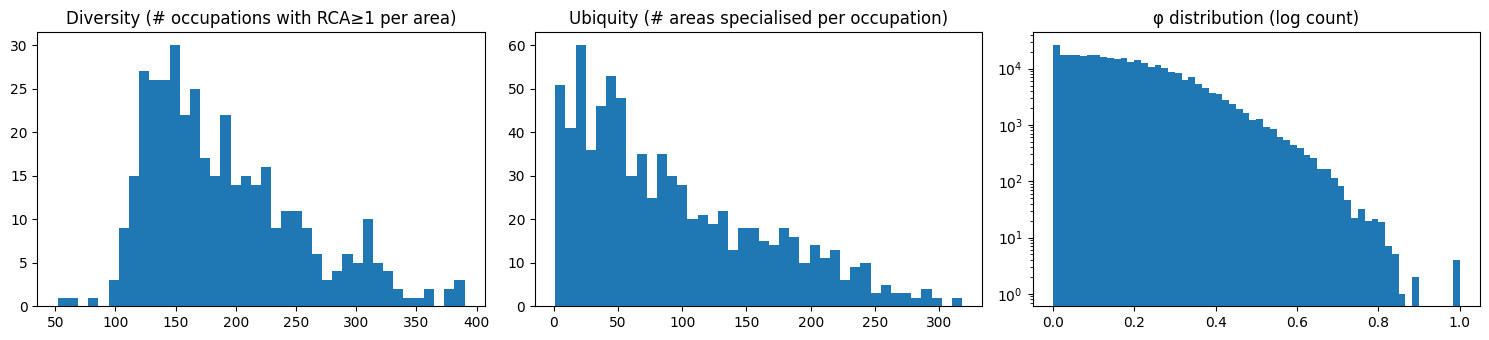

In [3]:
importlib.reload(cs)
MIN_REGION_EMP = 1000          # <- knob
occ_space = cs.build_occupation_space(oes, min_region_emp=MIN_REGION_EMP)
M, phi = occ_space["M"], occ_space["phi"]
print("M:", M.shape, " density of M:", round(M.mean(), 3))
print("phi: mean", phi[phi > 0].mean().round(3), " 99th pct", np.percentile(phi[phi > 0], 99).round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(M.sum(1), bins=40); ax[0].set_title("Diversity (# occupations with RCA≥1 per area)")
ax[1].hist(M.sum(0), bins=40); ax[1].set_title("Ubiquity (# areas specialised per occupation)")
ax[2].hist(phi[np.triu_indices_from(phi, 1)], bins=60, log=True); ax[2].set_title("φ distribution (log count)")
plt.tight_layout()

In [4]:
# Strongest occupation pairs
codes = occ_space["codes"]
iu = np.triu_indices_from(phi, 1)
top = np.argsort(-phi[iu])[:20]
pd.DataFrame({
    "a": [occ.loc[codes[i], "name"] for i in iu[0][top]],
    "b": [occ.loc[codes[j], "name"] for j in iu[1][top]],
    "phi": phi[iu][top].round(3),
})

,a,b,phi
0,Terrazzo Workers and Finishers,Camera and Photographic Equipment Repairers,1.000
1,Paperhangers,Camera and Photographic Equipment Repairers,1.000
2,Terrazzo Workers and Finishers,Paperhangers,1.000
3,Pediatric Surgeons,Watch and Clock Repairers,1.000
4,First-Line Supervisors of Retail Sales Workers,Retail Salespersons,0.886
5,Cashiers,Automotive Service Technicians and Mechanics,0.884
6,First-Line Supervisors of Retail Sales Workers,Cashiers,0.862
7,First-Line Supervisors of Food Preparation and Serving W...,First-Line Supervisors of Retail Sales Workers,0.846
8,First-Line Supervisors of Retail Sales Workers,Automotive Service Technicians and Mechanics,0.843
9,Retail Salespersons,Automotive Service Technicians and Mechanics,0.837


## 3. Complexity — PCI / ECI (method of reflections)

PCI is the eigenvector for the second-largest eigenvalue of $\tilde M^P = U^{-1}M^\top D^{-1}M$, using the py-ecomplexity sign and z-score conventions.

In [5]:
pci = pd.Series(occ_space["pci"], name="pci")
eci = pd.Series(occ_space["eci"], name="eci")
occ["pci"] = pci
display(occ.dropna(subset=["pci"]).sort_values("pci", ascending=False)[["name", "majorGroupName", "pci", "wage"]].head(15))
display(occ.dropna(subset=["pci"]).sort_values("pci")[["name", "majorGroupName", "pci", "wage"]].head(10))
reg = regions.join(eci, how="inner").join(pd.Series(occ_space["diversity"], name="diversity"))
display(reg.sort_values("eci", ascending=False).head(10))

,name,majorGroupName,pci,wage
47-2142,Paperhangers,Construction and Extraction,2.706545,51900
47-2053,Terrazzo Workers and Finishers,Construction and Extraction,2.706545,62330
49-9061,Camera and Photographic Equipment Repairers,"Installation, Maintenance, and Repair",2.706545,53420
49-9097,Signal and Track Switch Repairers,"Installation, Maintenance, and Repair",2.536618,84940
39-3021,Motion Picture Projectionists,Personal Care and Service,2.478092,50290
19-2011,Astronomers,"Life, Physical, and Social Science",2.399860,134430
29-1243,Pediatric Surgeons,Healthcare Practitioners and Technical,2.335013,450810
49-9064,Watch and Clock Repairers,"Installation, Maintenance, and Repair",2.335013,62450
33-3052,Transit and Railroad Police,Protective Service,2.334880,91820
15-2021,Mathematicians,Computer and Mathematical,2.268373,122520


,name,majorGroupName,pci,wage
47-5043,"Roof Bolters, Mining",Construction and Extraction,-0.763987,74760
47-5049,"Underground Mining Machine Operators, All Other",Construction and Extraction,-0.712530,67830
47-5044,"Loading and Moving Machine Operators, Underground Mining",Construction and Extraction,-0.632598,68470
45-4023,Log Graders and Scalers,"Farming, Fishing, and Forestry",-0.369821,48130
33-3051,Police and Sheriff's Patrol Officers,Protective Service,-0.218260,79320
35-3031,Waiters and Waitresses,Food Preparation and Serving Related,-0.208936,38360
41-2031,Retail Salespersons,Sales and Related,-0.204848,37150
41-1011,First-Line Supervisors of Retail Sales Workers,Sales and Related,-0.203975,52350
51-4121,"Welders, Cutters, Solderers, and Brazers",Production,-0.203023,55100
49-1011,"First-Line Supervisors of Mechanics, Installers, and Rep...","Installation, Maintenance, and Repair",-0.202926,82930


,name,regionType,eci,diversity
metro-new-york-newark-jersey-city-ny-nj,"New York-Newark-Jersey City, NY-NJ",Metro,3.174347,390
metro-washington-arlington-alexandria-dc-va-md-wv,"Washington-Arlington-Alexandria, DC-VA-MD-WV",Metro,3.095400,319
metro-san-francisco-oakland-fremont-ca,"San Francisco-Oakland-Fremont, CA",Metro,2.827379,360
metro-seattle-tacoma-bellevue-wa,"Seattle-Tacoma-Bellevue, WA",Metro,2.768132,349
metro-los-angeles-long-beach-anaheim-ca,"Los Angeles-Long Beach-Anaheim, CA",Metro,2.628227,386
metro-boston-cambridge-newton-ma-nh,"Boston-Cambridge-Newton, MA-NH",Metro,2.559804,359
metro-dallas-fort-worth-arlington-tx,"Dallas-Fort Worth-Arlington, TX",Metro,2.460291,323
metro-philadelphia-camden-wilmington-pa-nj-de-md,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",Metro,2.453642,383
metro-san-jose-sunnyvale-santa-clara-ca,"San Jose-Sunnyvale-Santa Clara, CA",Metro,2.418181,256
metro-atlanta-sandy-springs-roswell-ga,"Atlanta-Sandy Springs-Roswell, GA",Metro,2.404015,325


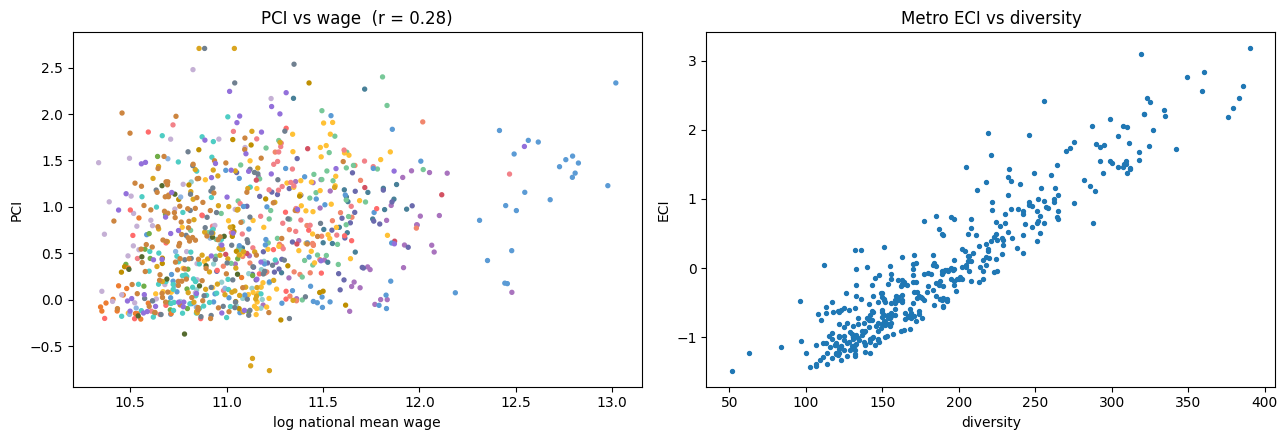

In [6]:
d = occ.dropna(subset=["pci", "wage"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(np.log(d.wage), d.pci, s=8, c=[MG_COLOR.get(g, "#999") for g in d.majorGroupId])
ax[0].set_xlabel("log national mean wage"); ax[0].set_ylabel("PCI")
ax[0].set_title(f"PCI vs wage  (r = {np.corrcoef(np.log(d.wage), d.pci)[0,1]:.2f})")
ax[1].scatter(reg.diversity, reg.eci, s=8); ax[1].set_xlabel("diversity"); ax[1].set_ylabel("ECI")
ax[1].set_title("Metro ECI vs diversity")
plt.tight_layout()

## 4. Job Space — jobs × O\*NET tasks, wage-seeded JCI / TCI

This ports `Job-Task Final.Rmd` §4.1.3. The job × DWA matrix uses binary "Model 1". The iteration starts from wages, $K_{J,1}=w_J$, and applies $JCI = \tilde M_{JJ}^{\,n}\,w_J$ with $\tilde M_{JJ} = D_J^{-1} M D_T^{-1} M^\top$.

jobs x DWAs: (768, 2072)   coverage of OES occupations: 768/819


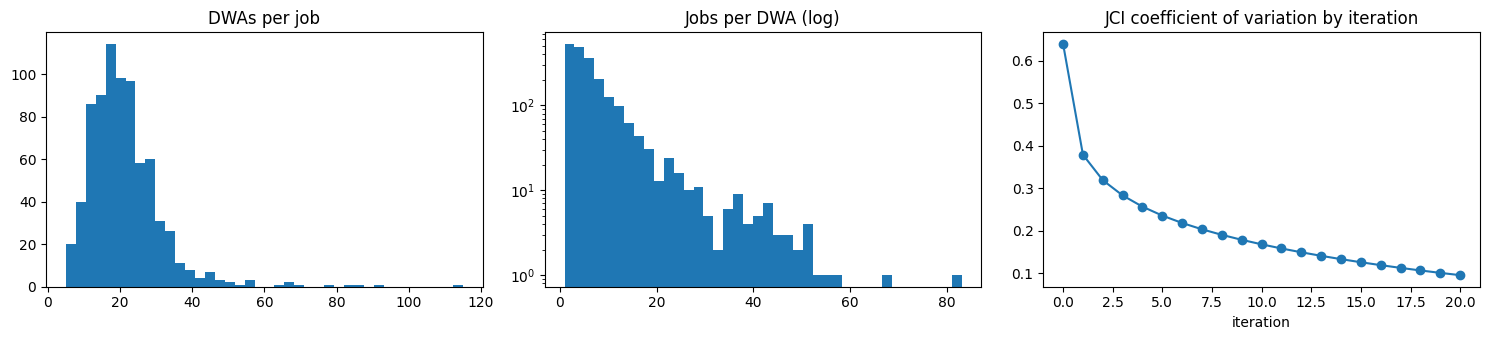

In [7]:
importlib.reload(cs)
pairs, dwa_titles = cs.load_onet_job_dwa(ONET_ZIP)
N_ITER = 20                    # <- knob (research used 20)
job_space = cs.build_job_space(oes, pairs, n_iter=N_ITER)
Mj = job_space["M"]
print("jobs x DWAs:", Mj.shape, f"  coverage of OES occupations: {len(job_space['codes'])}/{len(occ)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(Mj.sum(1), bins=40); ax[0].set_title("DWAs per job")
ax[1].hist(Mj.sum(0), bins=40, log=True); ax[1].set_title("Jobs per DWA (log)")
ax[2].plot(job_space["history"], marker="o"); ax[2].set_title("JCI coefficient of variation by iteration")
ax[2].set_xlabel("iteration")
plt.tight_layout()

In [8]:
occ["jci"] = pd.Series(job_space["jci"])
dj = occ.dropna(subset=["jci"])
display(dj.sort_values("jci", ascending=False)[["name", "majorGroupName", "jci", "wage"]].head(15))
display(dj.sort_values("jci")[["name", "majorGroupName", "jci", "wage"]].head(10))
tci = pd.Series(job_space["tci"]).sort_values(ascending=False)
display(pd.DataFrame({"task (DWA)": [dwa_titles[t] for t in tci.index[:15]], "TCI": tci.values[:15].round(0)}))

,name,majorGroupName,jci,wage
29-1041,Optometrists,Healthcare Practitioners and Technical,102692.856111,140940
29-1213,Dermatologists,Healthcare Practitioners and Technical,102682.539020,347810
29-1241,"Ophthalmologists, Except Pediatric",Healthcare Practitioners and Technical,102533.764274,301500
29-1217,Neurologists,Healthcare Practitioners and Technical,102531.819818,286310
29-1242,"Orthopedic Surgeons, Except Pediatric",Healthcare Practitioners and Technical,102483.020074,365060
29-1081,Podiatrists,Healthcare Practitioners and Technical,102477.575376,163960
29-1171,Nurse Practitioners,Healthcare Practitioners and Technical,102421.061155,132000
29-1299,"Healthcare Diagnosing or Treating Practitioners, All Other",Healthcare Practitioners and Technical,102415.252271,128680
29-1223,Psychiatrists,Healthcare Practitioners and Technical,102388.363415,269120
29-1291,Acupuncturists,Healthcare Practitioners and Technical,102381.489787,89750


,name,majorGroupName,jci,wage
51-3023,Slaughterers and Meat Packers,Production,71256.546321,40710
51-3022,"Meat, Poultry, and Fish Cutters and Trimmers",Production,71811.837572,38640
51-6092,Fabric and Apparel Patternmakers,Production,71837.452590,71630
51-6052,"Tailors, Dressmakers, and Custom Sewers",Production,71909.671666,44050
51-6031,Sewing Machine Operators,Production,71971.962715,36680
51-4192,"Layout Workers, Metal and Plastic",Production,71984.107010,65770
51-9194,Etchers and Engravers,Production,72015.233427,43280
51-4035,"Milling and Planing Machine Setters, Operators, and Tend...",Production,72048.639194,52940
51-9031,"Cutters and Trimmers, Hand",Production,72053.847236,41960
51-4022,"Forging Machine Setters, Operators, and Tenders, Metal a...",Production,72103.878087,50900


,task (DWA),TCI
0,Advise patients on preventive care techniques.,102396.0
1,Schedule medical facility use.,102373.0
2,Treat chronic diseases or disorders.,102216.0
3,Prescribe treatments or therapies.,102152.0
4,Care for women during pregnancy and childbirth.,102087.0
5,Prescribe medications.,102069.0
6,Prescribe assistive medical devices or related treatments.,102061.0
7,Operate on patients to treat conditions.,102008.0
8,Order medical diagnostic or clinical tests.,101994.0
9,Analyze test data or images to inform diagnosis or treat...,101974.0


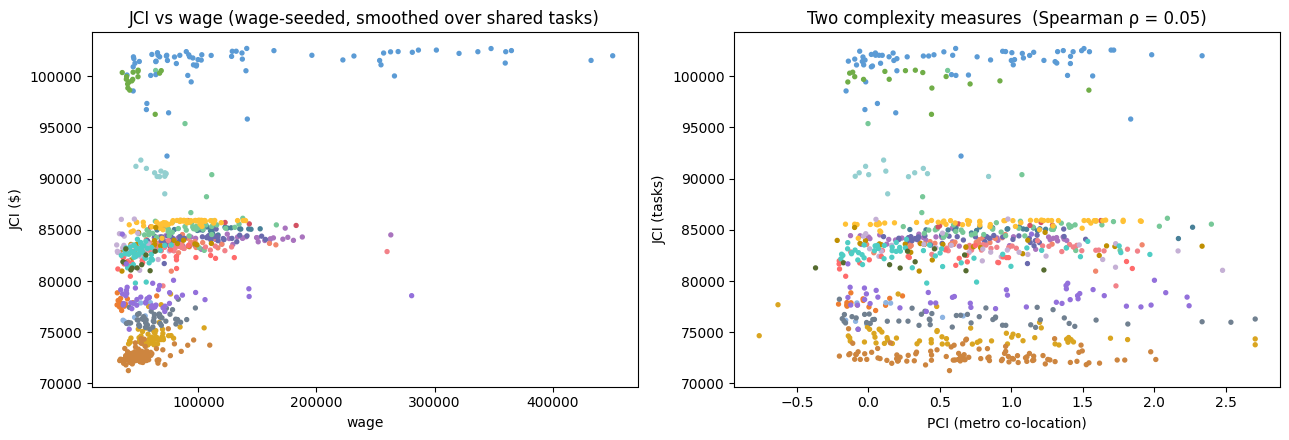

In [9]:
from scipy.stats import spearmanr
both = occ.dropna(subset=["pci", "jci", "wage"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
c = [MG_COLOR.get(g, "#999") for g in both.majorGroupId]
ax[0].scatter(both.wage, both.jci, s=8, c=c); ax[0].set_xlabel("wage"); ax[0].set_ylabel("JCI ($)")
ax[0].set_title("JCI vs wage (wage-seeded, smoothed over shared tasks)")
ax[1].scatter(both.pci, both.jci, s=8, c=c); ax[1].set_xlabel("PCI (metro co-location)"); ax[1].set_ylabel("JCI (tasks)")
rho = spearmanr(both.pci, both.jci).correlation
ax[1].set_title(f"Two complexity measures  (Spearman ρ = {rho:.2f})")
plt.tight_layout()

## 5. Making the graph readable — backbone, layout, clusters

These are the knobs to play with:
- `TARGET_AVG_DEGREE`: the maximum spanning tree plus each node's top-k links, with k chosen to reach this average degree.
- `SEED`: the layout seed.
- `RES_HIGH` and `RES_LOW`: Louvain resolutions for the high- and low-aggregation clusters. Higher values give more, smaller clusters.

In [10]:
importlib.reload(cs)
TARGET_AVG_DEGREE = 4.0   # <- knob
SEED = 42                 # <- knob
RES_HIGH, RES_LOW = 0.6, 1.0   # <- knobs
LAYOUT_METHOD = "kk_spring"    # <- knob: "kk_spring" (site default) or "kk_fa2" (ForceAtlas2, more separated)

def build_layout(space, kind):
    codes = space["codes"]; n = len(codes)
    edges, k, cutoff, mst = cs.backbone(space["phi"], TARGET_AVG_DEGREE)
    xy = cs.layout(n, edges, mst, seed=SEED, method=LAYOUT_METHOD)
    cont, country = cs.clusters(n, edges, seed=SEED, res_high=RES_HIGH, res_low=RES_LOW)
    print(f"{kind}: n={n}, links={len(edges)}, top-k={k}, φ cutoff={cutoff:.3f}, "
          f"{cont.max()+1} high / {country.max()+1} low clusters")
    return dict(codes=codes, edges=edges, xy=xy, cont=cont, country=country)

def plot_space(L, color="sector", values=None, highlight=None, title="", ax=None, hulls=True):
    ax = ax or plt.subplots(figsize=(13, 9.75))[1]
    xy = L["xy"]
    for i, j, w in L["edges"]:
        ax.plot(*xy[[i, j]].T, color="#ccc", lw=0.4, zorder=1)
    if hulls:
        for lab in np.unique(L["cont"]):
            poly = np.array(cs.hull(xy[L["cont"] == lab], pad=10))
            ax.fill(*poly.T, color="#000", alpha=0.04, zorder=0)
    if color == "sector":
        c = [MG_COLOR.get(occ.loc[code, "majorGroupId"], "#999") for code in L["codes"]]
        sc = ax.scatter(*xy.T, s=14, c=c, zorder=2, edgecolors="none")
    elif color == "cluster":
        cmap = plt.get_cmap("tab20")
        sc = ax.scatter(*xy.T, s=14, c=[cmap(v % 20) for v in L["cont"]], zorder=2, edgecolors="none")
    else:
        v = np.array([values.get(code, np.nan) for code in L["codes"]])
        sc = ax.scatter(*xy.T, s=14, c=v, cmap="viridis", zorder=2, edgecolors="none")
        plt.colorbar(sc, ax=ax, shrink=0.6, label=color)
    if highlight is not None:
        mask = np.array([code in highlight for code in L["codes"]])
        ax.scatter(*xy[~mask].T, s=16, c="#eee", zorder=3, edgecolors="none")
    # label the largest occupations
    emp = np.array([occ.loc[code, "nat_emp"] or 0 for code in L["codes"]])
    for i in np.argsort(-emp)[:25]:
        ax.annotate(occ.loc[L["codes"][i], "name"][:28], xy[i], fontsize=6.5, alpha=0.8,
                    xytext=(3, 3), textcoords="offset points", zorder=4)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    return ax

L_occ = build_layout(occ_space, "occupation")
L_job = build_layout(job_space, "job")

occupation: n=809, links=1929, top-k=3, φ cutoff=0.025, 8 high / 62 low clusters


job: n=768, links=1703, top-k=3, φ cutoff=0.050, 16 high / 85 low clusters


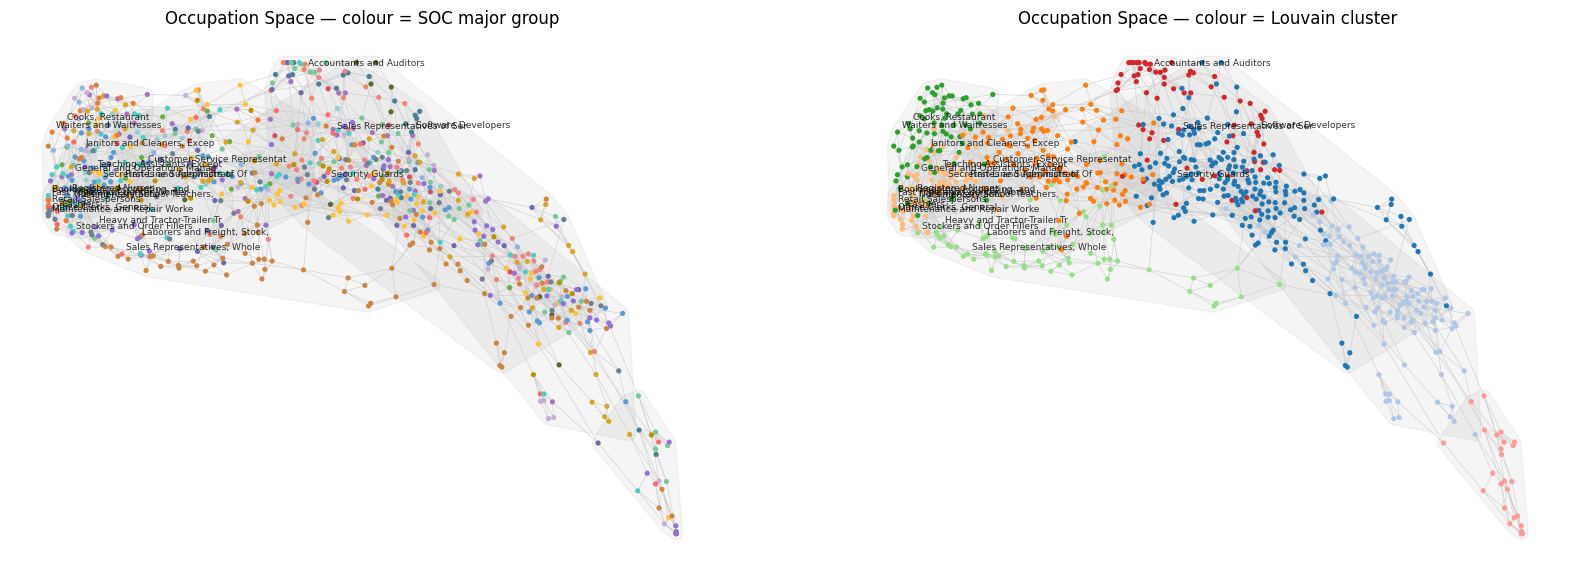

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
plot_space(L_occ, ax=ax[0], title="Occupation Space — colour = SOC major group")
plot_space(L_occ, color="cluster", ax=ax[1], title="Occupation Space — colour = Louvain cluster");

The sector colours are mixed in the Occupation Space, but the Louvain clusters sit in coherent regions of the map (modularity ≈ 0.75). Metros co-specialise **across** SOC families, for example a tourism cluster or a health-plus-education hub. The Job Space, by contrast, groups occupations largely within families, because shared tasks follow the occupational classification.

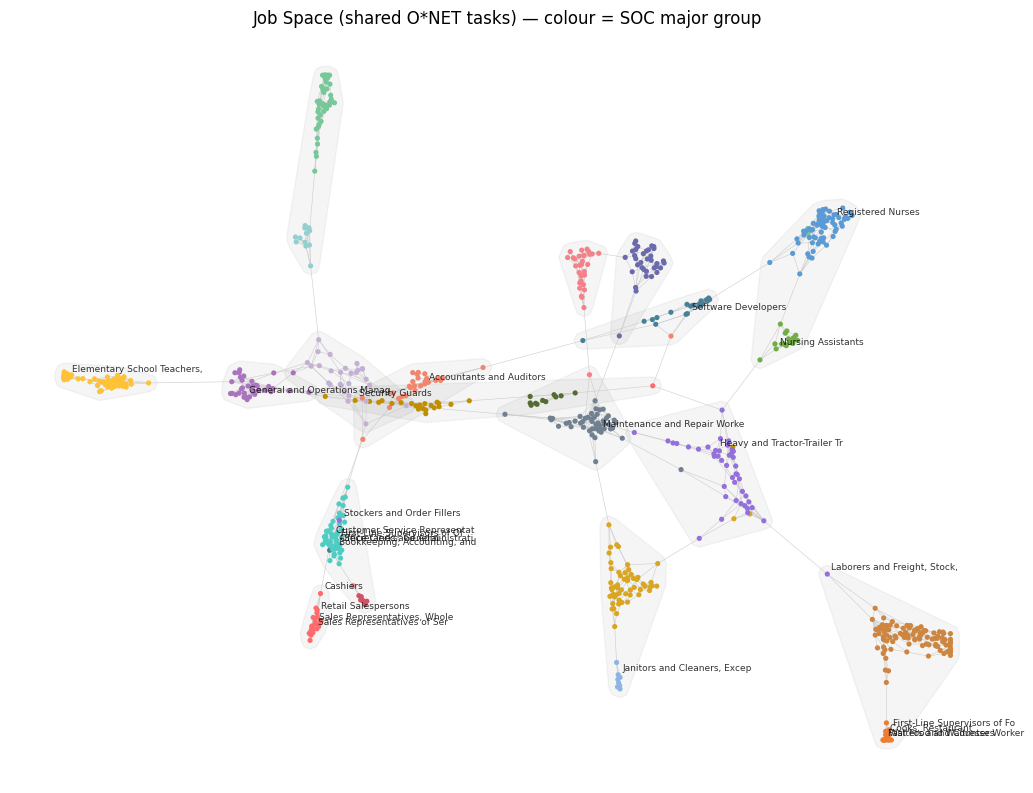

In [12]:
plot_space(L_job, title="Job Space (shared O*NET tasks) — colour = SOC major group");

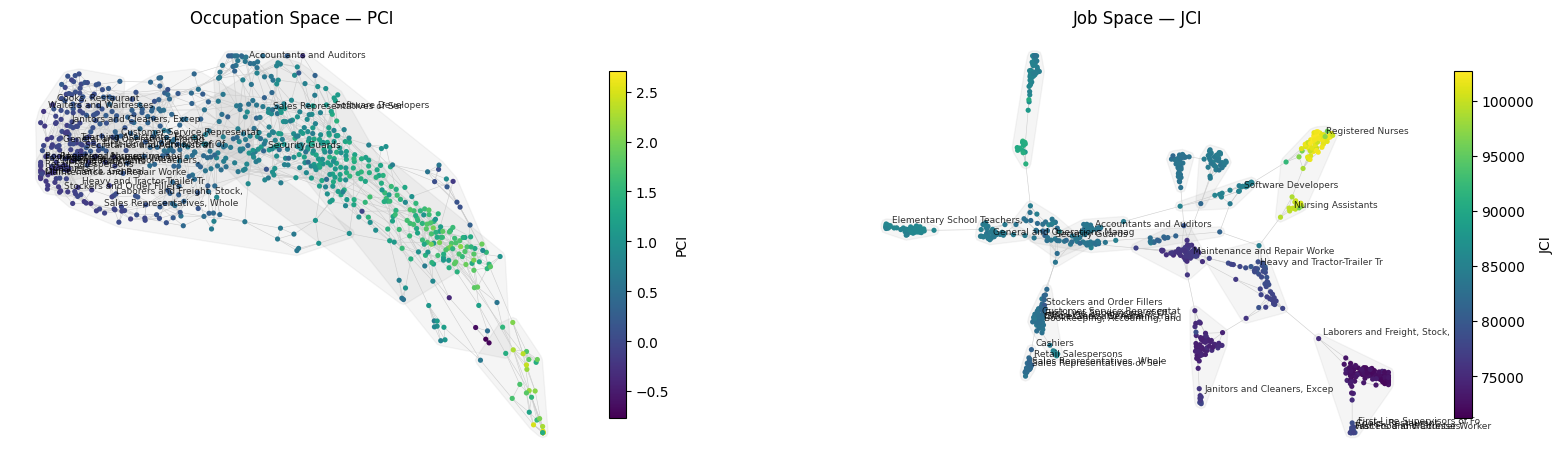

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
plot_space(L_occ, color="PCI", values=occ_space["pci"], ax=ax[0], title="Occupation Space — PCI")
plot_space(L_job, color="JCI", values=job_space["jci"], ax=ax[1], title="Job Space — JCI");

## 6. A region on the space and its propensity

Occupations where the region has **RCA ≥ 1** are shown in colour; the rest are grey.

**Propensity**, also called relatedness density, measures how close each *absent* occupation sits to what the region already does:
$$\omega_{cp} = \frac{\sum_{p'} M_{cp'}\,\phi_{pp'}}{\sum_{p'} \phi_{pp'}}$$
The table lists the absent occupations with the highest ω. These are the region's most feasible next occupations.

Austin-Round Rock-San Marcos, TX | ECI 2.15 | 299 occupations with RCA≥1



Top propensity (absent, most related) — Occupation Space


,occupation,ω,PCI,JCI
49-9095,Manufactured Building and Mobile Home Installers,0.555,-0.16,75909.0
47-5051,"Rock Splitters, Quarry",0.462,-0.03,74048.0
15-2041,Statisticians,0.460,1.06,85274.0
19-3099,"Social Scientists and Related Workers, All Other",0.459,0.60,85472.0
17-1021,Cartographers and Photogrammetrists,0.456,1.20,83745.0
11-9121,Natural Sciences Managers,0.453,0.59,85158.0
19-1023,Zoologists and Wildlife Biologists,0.452,0.66,84750.0
19-1029,"Biological Scientists, All Other",0.450,0.48,85206.0
19-3039,"Psychologists, All Other",0.448,1.07,90376.0
19-4021,Biological Technicians,0.447,0.54,84508.0



Top propensity (absent, most related) — Job Space


,occupation,ω,PCI,JCI
15-2041,Statisticians,0.746,1.06,85274.0
17-1021,Cartographers and Photogrammetrists,0.737,1.20,83745.0
15-2021,Mathematicians,0.703,2.27,85247.0
27-2041,Music Directors and Composers,0.690,1.41,83559.0
37-3012,"Pesticide Handlers, Sprayers, and Applicators, Vegetation",0.658,0.52,76454.0
11-3013,Facilities Managers,0.655,0.14,84059.0
25-1031,"Architecture Teachers, Postsecondary",0.652,1.58,85891.0
25-1111,"Criminal Justice and Law Enforcement Teachers, Postsecon...",0.651,1.21,85945.0
25-1043,"Forestry and Conservation Science Teachers, Postsecondary",0.651,1.91,85822.0
25-1041,"Agricultural Sciences Teachers, Postsecondary",0.650,1.54,85899.0


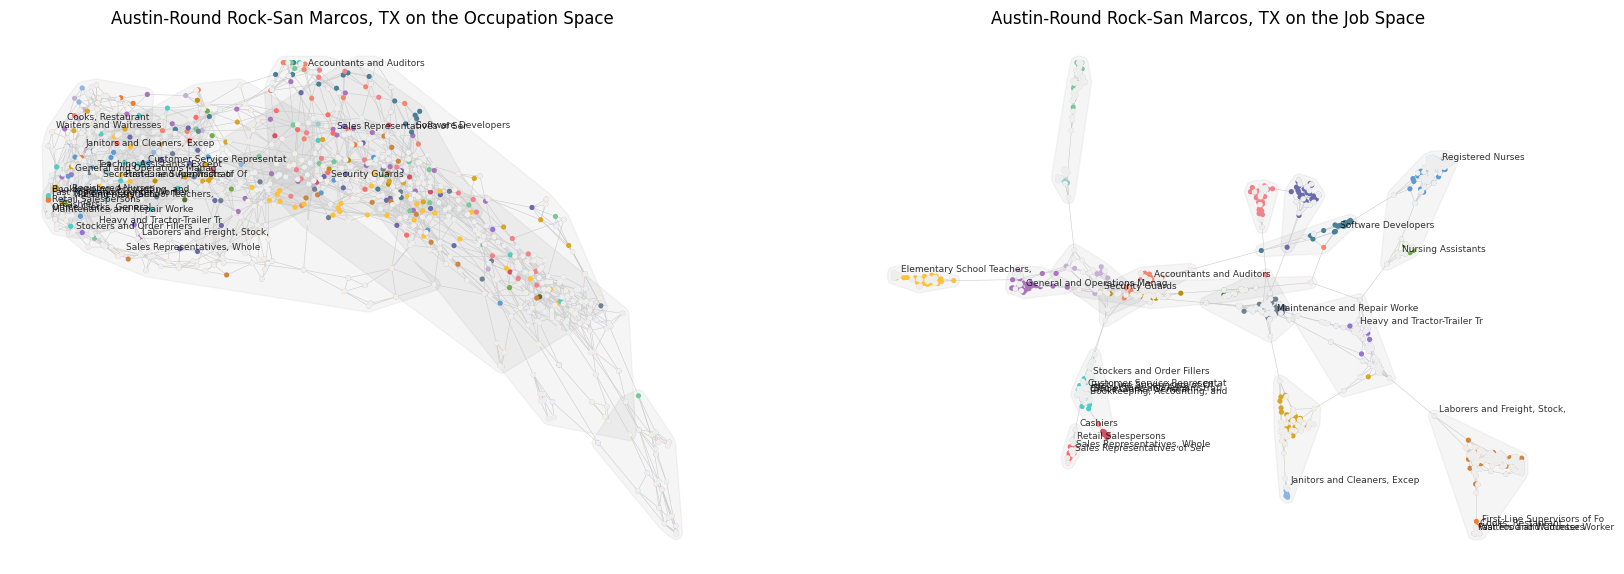

In [14]:
REGION = "metro-austin-round-rock-san-marcos-tx"     # <- knob: any regionId (see regions table)
matches = [r for r in occ_space["region_ids"] if r == REGION] or \
          [r for r in occ_space["region_ids"] if REGION.split("-")[1] in r]
rid = matches[0]; ri = occ_space["region_ids"].index(rid)
present = {c for c, m in zip(occ_space["codes"], occ_space["M"][ri]) if m}
print(oes["regions"][rid]["name"], "| ECI", round(occ_space["eci"][rid], 2), "|", len(present), "occupations with RCA≥1")

def propensity(space, present_codes):
    codes, P = space["codes"], space["phi"]
    m = np.array([c in present_codes for c in codes], dtype=float)
    return pd.Series((P @ m) / P.sum(1), index=codes)

fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
plot_space(L_occ, highlight=present, ax=ax[0], title=f"{oes['regions'][rid]['name']} on the Occupation Space")
plot_space(L_job, highlight=present, ax=ax[1], title=f"{oes['regions'][rid]['name']} on the Job Space")

for name, space in (("Occupation Space", occ_space), ("Job Space", job_space)):
    w = propensity(space, present)
    w = w[[c not in present for c in w.index]].sort_values(ascending=False).head(12)
    print(f"\nTop propensity (absent, most related) — {name}")
    display(pd.DataFrame({"occupation": occ.loc[w.index, "name"], "ω": w.round(3),
                          "PCI": occ.loc[w.index, "pci"].round(2), "JCI": occ.loc[w.index, "jci"].round(0)}))

## 7. Export what the website uses (to `outputs/`, not the site data)

In [15]:
importlib.reload(cs)
summary = cs.compute_all(DATA_DIR, ONET_ZIP, out_dir=OUT_DIR, seed=SEED)
summary

  Loading OES level-4 data...


    819 occupations, 448 regions
  Occupation Space (metro co-specialisation)...


    809 occupations x 393 metro/nonmetro areas
  Job Space (shared O*NET tasks)...


    768 jobs x 2072 DWAs
  Layout + clusters: occupation space...


    space-us-2024-occupation.json: {'nNodes': 809, 'nLinks': 1929, 'avgDegree': 4.77, 'topK': 3, 'phiCutoff': 0.025, 'nContinents': 8, 'nCountries': 62}
  Layout + clusters: job space...


    space-us-2024-job.json: {'nNodes': 768, 'nLinks': 1703, 'avgDegree': 4.43, 'topK': 3, 'phiCutoff': 0.05, 'nContinents': 16, 'nCountries': 85}
    complexity-us-2024.json: {'corrPciLogWage': 0.284, 'corrJciLogWage': 0.454, 'nPci': 809, 'nJci': 768, 'nRegionsEci': 393, 'nDwa': 2072}


{'occupation': {'nNodes': 809,
  'nLinks': 1929,
  'avgDegree': 4.77,
  'topK': 3,
  'phiCutoff': 0.025,
  'nContinents': 8,
  'nCountries': 62},
 'job': {'nNodes': 768,
  'nLinks': 1703,
  'avgDegree': 4.43,
  'topK': 3,
  'phiCutoff': 0.05,
  'nContinents': 16,
  'nCountries': 85},
 'complexity': {'corrPciLogWage': 0.284,
  'corrJciLogWage': 0.454,
  'nPci': 809,
  'nJci': 768,
  'nRegionsEci': 393,
  'nDwa': 2072}}